# 【無料公開中】LangChainのススメ【初心者お助けbook】【2025年4月最新版】
# 第三部　中編

## 事前準備

仮想環境の構築や、パッケージインストールなど

In [1]:
#1セル目

!pip uninstall -y google-generativeai
!pip install langchain==0.3.24 langchain_core==0.3.55 langchain_google_genai==2.1.3 httpx==0.28.1 requests==2.32.3 langchain-tavily==0.1.5 langgraph==0.3.31

Found existing installation: google-generativeai 0.8.4
Uninstalling google-generativeai-0.8.4:
  Successfully uninstalled google-generativeai-0.8.4
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.5/43.5 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 28.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 434.1/434.1 kB 32.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 145.2/145.2 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 73.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 63.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.3/47.3 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 97.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 194.8/194.8 kB 17.6 MB

## chapter15 Tool Callingを利用したAIエージェントを実装する方法【initialize_agent/Agent Executorは使うな！】

5セル目まで実行してください。

In [2]:
# 2セル目

import os
import time
import operator
from typing import  Annotated
from typing_extensions import TypedDict, Annotated
from pydantic import BaseModel, Field

from langchain_google_genai import ChatGoogleGenerativeAI

from langchain_core.messages import HumanMessage, AIMessage, SystemMessage, AnyMessage
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_tavily import TavilySearch, TavilyExtract

from langgraph.types import Command
from langgraph.prebuilt import ToolNode
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver

#環境変数とパッケージの準備
from google.colab import userdata
os.environ["GOOGLE_API_KEY"] = userdata.get("GOOGLE_API_KEY")
os.environ["TAVILY_API_KEY"] = userdata.get("TAVILY_API_KEY")

In [3]:
# 3セル目

# geminiモデルを定義する
llm = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash-preview-04-17",
    temperature=0,
    max_retries=0,
)

print(llm.invoke("Hello, world!"))

content='Hello there!\n\nAh, the classic "Hello, world!" greeting. It\'s great to hear from you.\n\nHow can I help you today?' additional_kwargs={} response_metadata={'prompt_feedback': {'block_reason': 0, 'safety_ratings': []}, 'finish_reason': 'STOP', 'model_name': 'models/gemini-2.5-flash-preview-04-17', 'safety_ratings': []} id='run-7e6555b8-f721-4f4a-9903-98d406ef91c4-0' usage_metadata={'input_tokens': 5, 'output_tokens': 32, 'total_tokens': 445, 'input_token_details': {'cache_read': 0}}


In [4]:
#4セル目

tavily_search_tool = TavilySearch(
    max_results=10,
    topic="general",
)

tavily_extract_tool = TavilyExtract()

tools = [
    tavily_search_tool,
    tavily_extract_tool
]

system_prompt = """
あなたは日本語を話す優秀なアシスタントです。回答には必ず日本語で答えてください。また考える過程も出力してください。
私たちは「tavily_search_tool」と「tavily_extract_tool」という2つのツールを持っています。
tavily_search_toolは、Google検索を行い、上位5件のURLや概要を取得するツールです。どんなwebサイトがあるかを浅く拾う場合にはこちらを利用します
tavily_extract_toolは、URLを指定して、ページの内容を抽出するツールです。特定のWebサイトのURLがわかっており、詳細に内容を取得する場合はこちらを利用します。
適切に利用してユーザからの質問に回答してください。
"""


# messageを作成する
message = [
    SystemMessage(content=system_prompt),
    MessagesPlaceholder("messages"),
]

# messageからプロンプトを作成
prompt = ChatPromptTemplate.from_messages(message)

#chainを作成
chain = prompt | llm.bind_tools(tools)

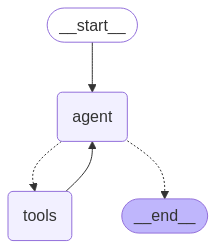

In [5]:
#5セル目

class GraphState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]

def create_langgraph(tools):

    def should_continue(state: GraphState):
        messages = state["messages"]
        last_message = messages[-1]
        if last_message.tool_calls:
            return "tools"
        return END

    def call_llm(state: GraphState):
        response = chain.invoke({"messages":state["messages"]})
        print("====response====")
        print(response)
        return {"messages": [response]}

    tool_node = ToolNode(tools)

    workflow = StateGraph(GraphState)
    workflow.add_node("agent", call_llm)
    workflow.add_node("tools", tool_node)

    workflow.add_edge(START, "agent")
    workflow.add_conditional_edges("agent", should_continue, ["tools", END])
    workflow.add_edge("tools", "agent")

    memory = MemorySaver()
    graph = workflow.compile(checkpointer=memory)
    return graph

graph = create_langgraph(tools)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [6]:
#6セル目

while True:
    query = input("質問を入力してください: ")

    if query.lower() in ["exit", "quit"]:
        print("終了します。")
        break

    print("=================================")
    print("質問:", query)

    input_query = [HumanMessage(
            [
                {
                    "type": "text",
                    "text": f"{query}"
                },
            ]
        )]

    response = graph.invoke({"messages": input_query} ,config={"configurable": {"thread_id": "12345"}})

    #デバック用
    print("response: ", response)

    print("=================================")
    print("AIの回答",response["messages"][-1].content)




質問を入力してください: 最新の動画生成AI（オープンモデル）においてアニメ風の動画を品質高く生成することのできるモデルを調査してください。出力の際には精度に関して調査して上で、現時点で最も高性能なモデルを教えてください。さらにそのモデルの利用方法などについても知りたいです。また商用利用が可能なライセンスに絞ってください。
質問: 最新の動画生成AI（オープンモデル）においてアニメ風の動画を品質高く生成することのできるモデルを調査してください。出力の際には精度に関して調査して上で、現時点で最も高性能なモデルを教えてください。さらにそのモデルの利用方法などについても知りたいです。また商用利用が可能なライセンスに絞ってください。
====response====
content='はい、承知いたしました。最新の動画生成AIオープンモデルで、アニメ風の動画を高品質に生成でき、かつ商用利用可能なライセンスを持つモデルについて調査し、現時点で最も高性能と思われるモデルとその利用方法についてご案内します。\n\nまず、関連情報を検索します。' additional_kwargs={'function_call': {'name': 'tavily_search', 'arguments': '{"search_depth": "advanced", "query": "\\u6700\\u65b0 \\u52d5\\u753b\\u751f\\u6210AI \\u30aa\\u30fc\\u30d7\\u30f3\\u30e2\\u30c7\\u30eb \\u30a2\\u30cb\\u30e1 \\u5546\\u7528\\u5229\\u7528 \\u9ad8\\u54c1\\u8cea", "time_range": "year"}'}} response_metadata={'prompt_feedback': {'block_reason': 0, 'safety_ratings': []}, 'finish_reason': 'STOP', 'model_name': 'models/gemini-2.5-flash-preview-04-17', 'safety_ratings': []} id='run-7e2a3b47-54fc-4ae1-8be7-5